# Stroke Prediction — Data Understanding & Cleaning

**Author:** Nephtalem Woldeyohanes · ML Assignment 1 (Classification)

## 1. Context & goal
Stroke is a leading cause of death and disability. This notebook explores a patient dataset to find which health and lifestyle factors relate to stroke, and prepares a clean file for modelling.

| Item | Detail |
|---|---|
| Source | Kaggle — *Stroke Prediction Dataset* (fedesoriano) |
| Size | 5,110 patients × 12 columns |
| Target | `stroke` (1 = had a stroke, 0 = no stroke) |
| Features | 3 numeric (`age`, `avg_glucose_level`, `bmi`), 2 binary (`hypertension`, `heart_disease`), 5 categorical |

**Limitation:** the original source and collection method of the data are not documented.

**Outline:** 2. Setup · 3. Overview & quality checks · 4. Distributions · 5. Relationships with stroke · 6. Cleaning · 7. Save & summary

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

Raw_Path = Path("../data/raw") / "healthcare-dataset-stroke-data.csv"
Processed_Dir = Path("../data/processed")
Fig_Dir = Path("../reports/figures")
Processed_Dir.mkdir(parents=True, exist_ok=True)
Fig_Dir.mkdir(parents=True, exist_ok=True)

# default style for all plots
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["font.size"] = 11
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"

df = pd.read_csv(Raw_Path)

## 3. Overview & quality checks

In [2]:
print(df.shape)
df.head()

(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [4]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [5]:
df.isna().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [6]:
print("duplicate rows:", df.duplicated().sum())
print("duplicate ids:", df["id"].duplicated().sum())

duplicate rows: 0
duplicate ids: 0


In [7]:
# levels of each text column
for col in df.select_dtypes(exclude="number").columns:
    print(df[col].value_counts(), "\n")

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64 

ever_married
Yes    3353
No     1757
Name: count, dtype: int64 

work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64 

Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64 

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64 



stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    95.1
1     4.9
Name: proportion, dtype: float64


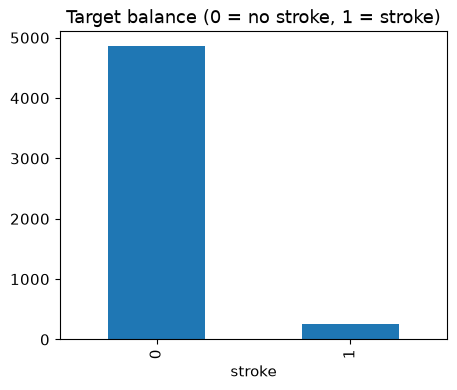

In [8]:
print(df["stroke"].value_counts())
print((df["stroke"].value_counts(normalize=True) * 100).round(1))

df["stroke"].value_counts().plot(kind="bar", figsize=(5, 4), title="Target balance (0 = no stroke, 1 = stroke)")
plt.savefig(Fig_Dir / "target_balance.png")
plt.show()

**Findings**
- No duplicate rows or ids. Only `bmi` has missing values (201, 3.9%).
- `gender` has a single `"Other"` row, which is too few to learn from.
- `smoking_status = "Unknown"` for 1,544 patients (682 of them are children); kept as its own category, not treated as missing.
- `bmi` reaches 97.6 (13 values > 60): suspicious, possibly entry errors, but kept and noted.
- **Strong class imbalance:** 249 strokes (4.9%) vs 4,861 (95.1%). A model that always predicts "no stroke" would score 95% accuracy, so **accuracy is not a useful metric** here.

## 4. Distributions

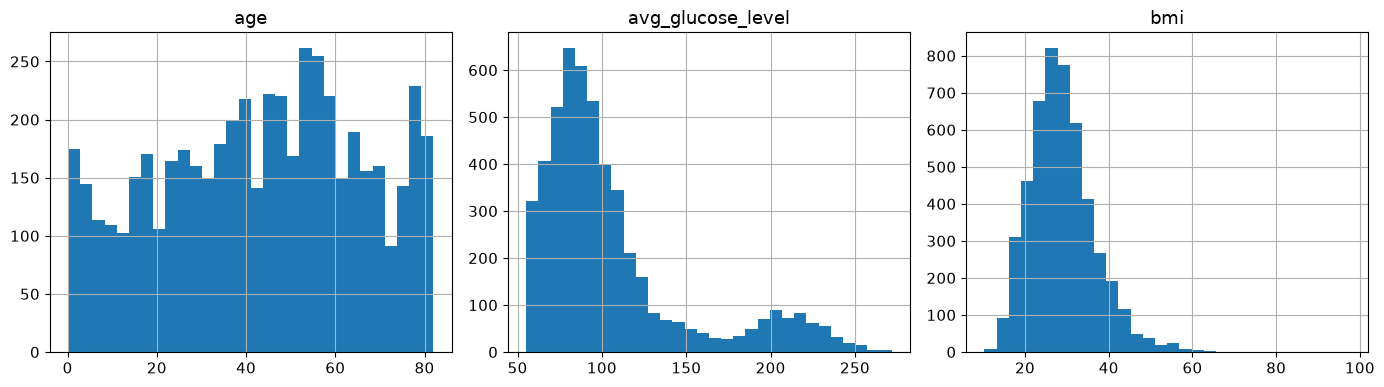

In [9]:
num_cols = ["age", "avg_glucose_level", "bmi"]

df[num_cols].hist(bins=30, layout=(1, 3), figsize=(14, 4))
plt.tight_layout()
plt.savefig(Fig_Dir / "numeric_distributions.png")
plt.show()

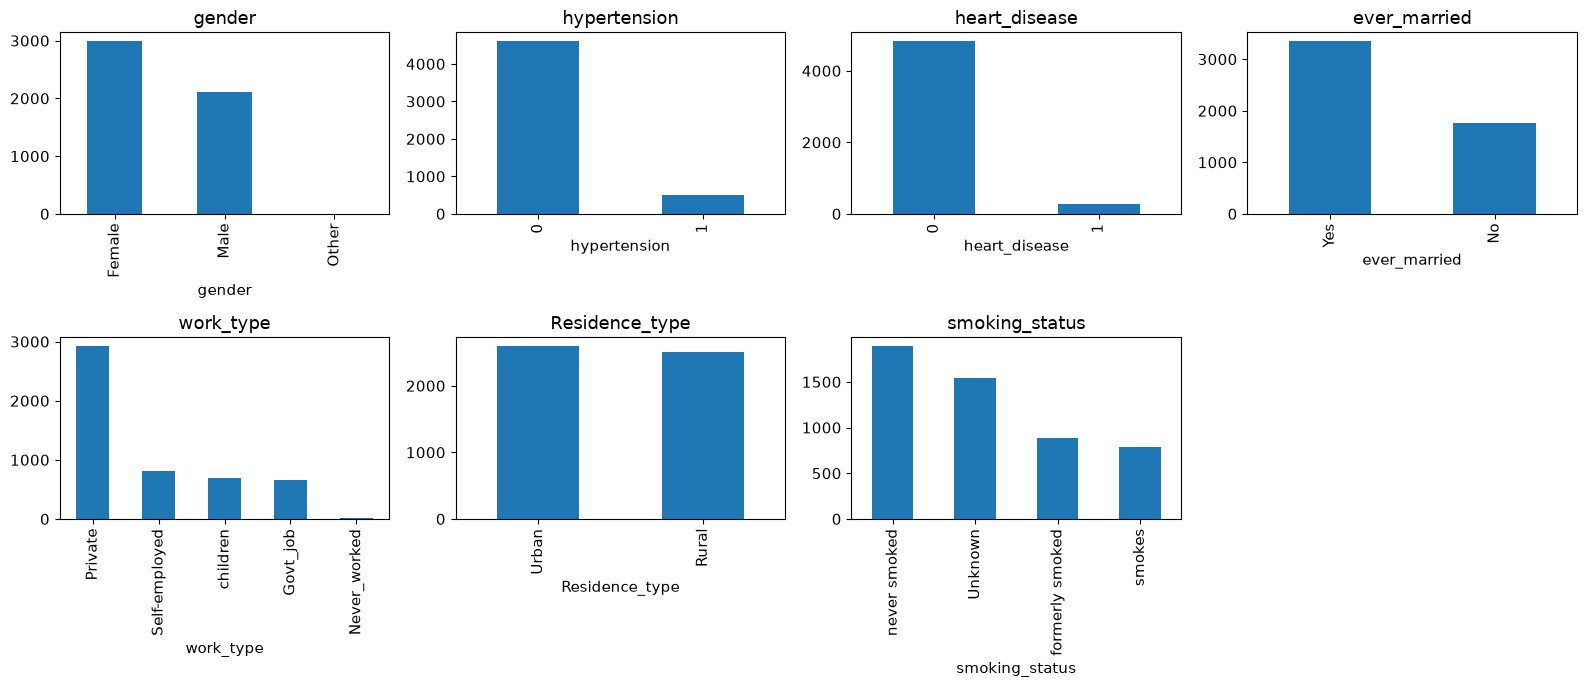

In [10]:
categorical_columns = ["gender", "hypertension", "heart_disease", "ever_married", "work_type", "Residence_type", "smoking_status"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for col, ax in zip(categorical_columns, axes.flat):
    df[col].value_counts().plot(kind="bar", ax=ax, title=col)
axes.flat[-1].axis("off")   # 7 plots in a 2x4 grid
plt.tight_layout()
plt.savefig(Fig_Dir / "categorical_counts.png")
plt.show()

**Findings**
- `age` covers 0–82 fairly evenly and includes infants (min 0.08).
- `avg_glucose_level` is right-skewed with a second hump above ~200 (likely diabetic patients).
- `bmi` is mildly right-skewed, centred around 28.
- Some categories are rare (`Never_worked` = 22), and there are more females (59%) than males.

## 5. Relationships with stroke

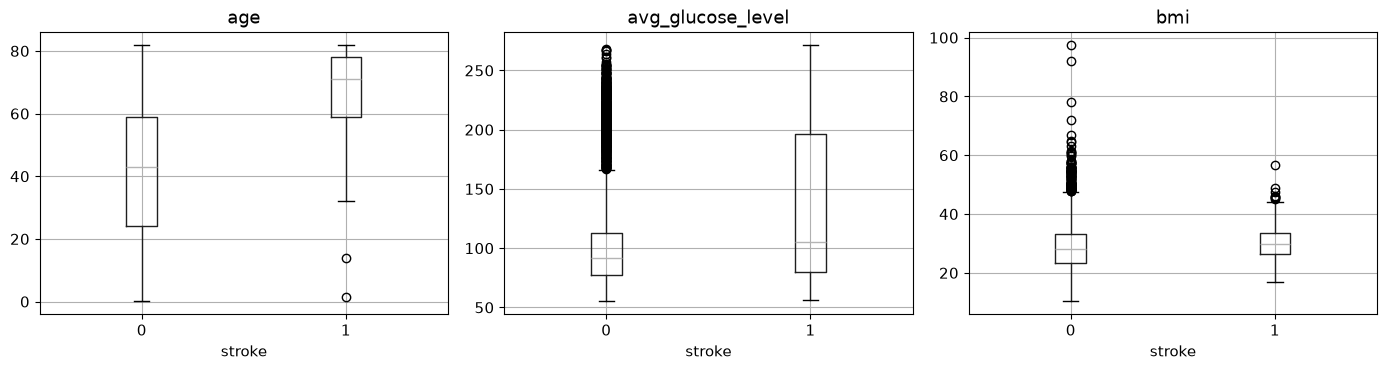

,age,avg_glucose_level,bmi
stroke,,,
0,43.0,91.47,28.0
1,71.0,105.22,29.7


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(num_cols, axes):
    df.boxplot(column=col, by="stroke", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("stroke")
plt.suptitle("")
plt.tight_layout()
plt.savefig(Fig_Dir / "numeric_by_stroke.png")
plt.show()

df.groupby("stroke")[num_cols].median()

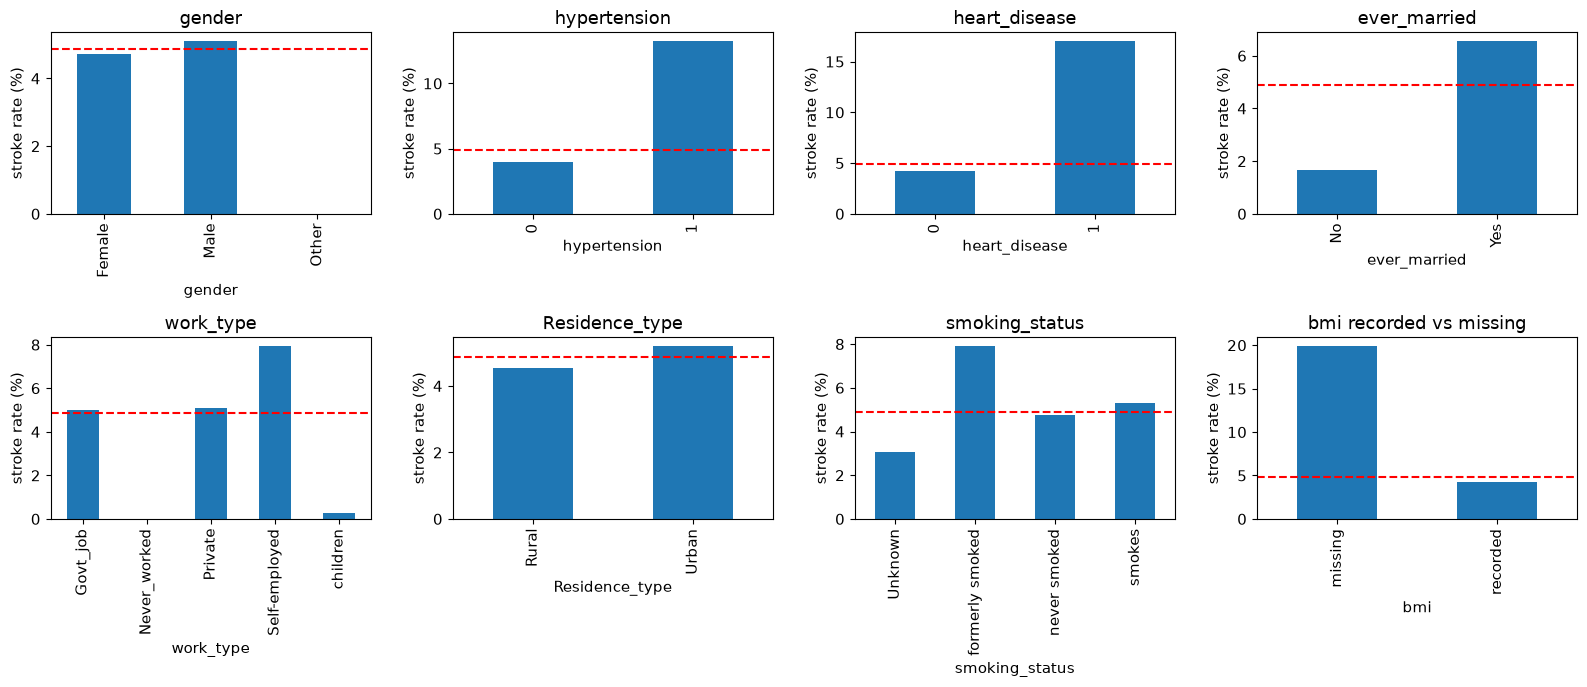

bmi
missing     0.199005
recorded    0.042575
Name: stroke, dtype: float64

In [12]:
# stroke rate (%) per category; red line = overall rate (4.9%)
overall = df["stroke"].mean() * 100
bmi_status = df["bmi"].isna().map({False: "recorded", True: "missing"}).rename("bmi")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for col, ax in zip(categorical_columns, axes.flat):
    (df.groupby(col)["stroke"].mean() * 100).plot(kind="bar", ax=ax, title=col)
(df.groupby(bmi_status)["stroke"].mean() * 100).plot(kind="bar", ax=axes.flat[-1], title="bmi recorded vs missing")
for ax in axes.flat:
    ax.axhline(overall, color="red", linestyle="--")
    ax.set_ylabel("stroke rate (%)")
plt.tight_layout()
plt.savefig(Fig_Dir / "stroke_rate_by_category.png")
plt.show()

df.groupby(bmi_status)["stroke"].mean()

stroke               1.000000
age                  0.245257
heart_disease        0.134914
avg_glucose_level    0.131945
hypertension         0.127904
bmi                  0.042374
Name: stroke, dtype: float64


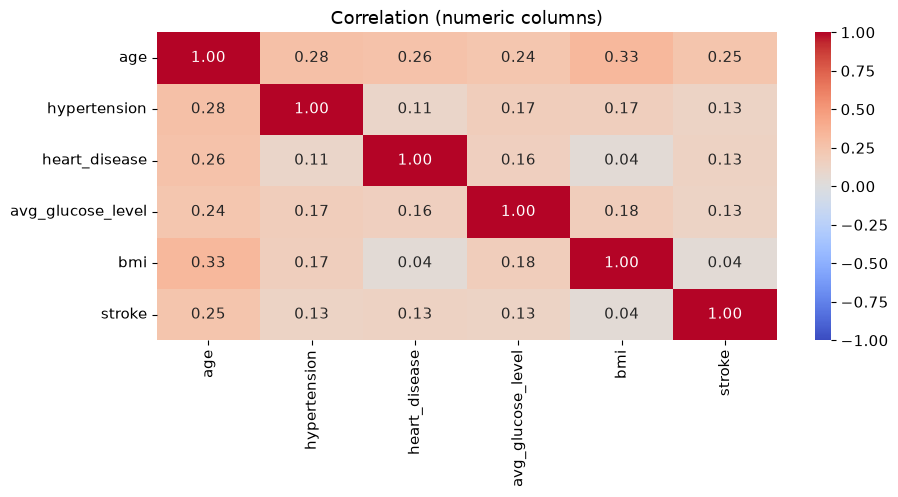

In [13]:
corr = df.drop(columns=["id"]).corr(numeric_only=True)
print(corr["stroke"].sort_values(ascending=False))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation (numeric columns)")
plt.savefig(Fig_Dir / "correlation.png")
plt.show()

**Findings**
- **Age is the strongest signal:** median age 71 for stroke patients vs 43; the stroke rate is 0.4% under 40 and 13.2% at 60+.
- Glucose is higher for stroke patients (median 105 vs 91); `bmi` barely differs (29.7 vs 28.0).
- `hypertension` (13.3% vs 4.0%) and `heart_disease` (17.0% vs 4.2%) clearly raise the rate.
- `ever_married` (6.6% vs 1.7%) and `work_type` (children 0.3%, self-employed 7.9%) mostly reflect **age**: married and self-employed people are older. They are related to stroke, not causes of it.
- `gender` and `Residence_type` show almost no difference.
- **Missing `bmi` is informative:** 19.9% stroke rate when `bmi` is missing vs 4.3% when recorded. These rows are kept, and a missing-indicator will be added when imputing.
- Numeric correlations are weak (max 0.25, age). Correlation only captures linear effects and ignores categories, so the stroke-rate plots are more informative.

## 6. Cleaning
Only fix what is wrong. Imputing `bmi` and encoding categories happen inside the model pipeline (after the train/test split) to avoid leakage.

**Outliers:** 13 patients have BMI > 60 and 434 have glucose > 200 mg/dL. Both are medically plausible (severe obesity, diabetes) and the glucose group carries real stroke signal, so they are **kept**, not removed. Scaling and the regularized linear model limit their influence.

In [14]:
df_clean = df.drop(columns=["id"])                                          # identifier, no predictive meaning
df_clean = df_clean[df_clean["gender"] != "Other"].reset_index(drop=True)   # single row, too few to learn from

print(df_clean.shape)
print(df_clean["gender"].value_counts())
print("bmi missing:", df_clean["bmi"].isna().sum())

(5109, 11)
gender
Female    2994
Male      2115
Name: count, dtype: int64
bmi missing: 201


## 7. Save & summary

In [15]:
clean_path = Processed_Dir / "stroke_clean.csv"
df_clean.to_csv(clean_path, index=False)

check = pd.read_csv(clean_path)
print(check.shape, check["bmi"].isna().sum())

(5109, 11) 201


**Summary for modelling**
1. **Target:** `stroke`, only 4.9% positive → stratified split and `StratifiedKFold`, `class_weight="balanced"`.
2. **Metric:** recall for the stroke class (missing a stroke is the costliest error), plus precision, F1, PR-AUC and the confusion matrix. Accuracy is not used.
3. **Features (10):** `age`, `avg_glucose_level`, `bmi`, `hypertension`, `heart_disease`, `gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status`.
4. **Pipeline:** median imputation for `bmi` with a missing-indicator, one-hot encoding for categories, scaling for linear models.
5. **Expected strongest predictors:** age, hypertension, heart disease, glucose.